In [1]:
from graph import create_graph

In [2]:
my_graph=create_graph()
my_graph_2=create_graph()
graph_mo=my_graph.compile()

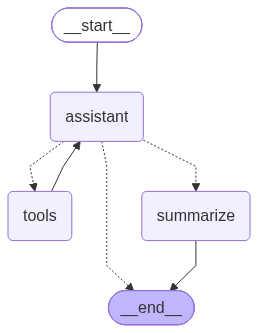

In [3]:
graph_mo


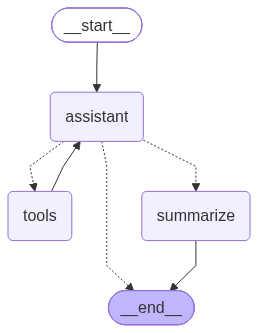

In [4]:
from IPython.display import Image,display
try:
    display(Image(graph_mo.get_graph().draw_mermaid_png()))
except exception as e:
    print('could not render png')

In [5]:
from langchain_core.messages import HumanMessage
turn_1 =graph_mo.invoke({
    'messages':[HumanMessage('i need a fix for pimples')]

})

turn_1['messages'][-1].pretty_print()

================================== Ai Message ==================================

[{'type': 'text', 'text': 'I understand dealing with pimples can be frustrating! To help me recommend the best product for you, could you tell me a little bit about your skin type (for example: is your skin oily, dry, or combination)?', 'extras': {'signature': 'AY89a1/mYOudnz6p7kdGB+4qvKz0FTbGwCjxImfhD/vAJ9oJ/3sC0hoUstlJptv1aI54yQ3qc0MGs69lPtsRjJJ7iwt7wvXN182JTXbF5cbLD35BJdz2RbAR+Tc='}}]


In [6]:
turn_2 =graph_mo.invoke({
    'messages':[HumanMessage('Which product did you just recommend?')]

})

turn_2['messages'][-1].pretty_print()

================================== Ai Message ==================================

[{'type': 'text', 'text': "Hello! I haven't recommended a product to you yet. \n\nTo help me find the best product for you, could you please tell me what kind of personal care or cosmetic concern you are looking to address today? (For example: skin care, hair care, body care, etc.)", 'extras': {'signature': 'AY89a1+BRS9EIJajLbwyrHAqDDSTYtPJXPXD2nWMYtHN+obuCBpVlQQsy7RX6qu1WvirqBw+DcovrSrHk8PVHpH2AUmuqSKkU2noNMDOm9x5MsCNfw3sv+zVpbo='}}]


In [7]:
print(f"Messages at the end of turn_1: ",len(turn_1['messages']))
print(f"Messages at the end of turn_2: ",len(turn_2['messages']))

Messages at the end of turn_1:  4
Messages at the end of turn_2:  2


In [8]:
from langgraph.checkpoint.memory import InMemorySaver 

checkpointer = InMemorySaver()
graph_m1 =my_graph_2.compile(checkpointer = checkpointer)

In [9]:
cfg = { "configurable":{'thread_id':"abc12"}}

In [10]:
from langchain_core.messages import HumanMessage
turn_1 = graph_m1.invoke(
    {
    'messages':[
        HumanMessage('i need a fix for pimples')
    ]

    },
    cfg
)
turn_1['messages'][-1].pretty_print()


================================== Ai Message ==================================

[{'type': 'text', 'text': 'I understand you are looking for a solution for pimples. To help me recommend the best product for you, could you please tell me what your skin type is (for example: oily, dry, combination, or sensitive)?', 'extras': {'signature': 'AY89a18WYsCXD31+nEBk4Ld3NUf46ywZvE/AjF1+OlszhMIZKUEEY1rX3sJxN7l018QPBzLDxIDtrU5GlP2XhCn8h1nuZ3g79sfe/bEOId8O1v85ppJB9S8N5/I='}}]


In [11]:
turn_2 =graph_m1.invoke({
    'messages':[HumanMessage('oily skin')]

},cfg)
turn_2['messages'][-1].pretty_print()

================================== Ai Message ==================================

[{'type': 'text', 'text': 'For oily skin prone to breakouts and excess shine, I recommend our **ClearBalance Oil Control Serum**. It is specifically formulated to help manage excess oil, support a balanced-looking complexion, and improve the appearance of pores.\n\nTo help you get started with your order, could you please share your full name, email address, and shipping address?', 'extras': {'signature': 'AY89a18J/hwy33jpmadKuWuPa3IJ0kFLLeaMbwYQclF9ogTTeLwDcgf1akkjHDNcMfztI5/uL/VzzmIVStnWRKw1ZoIo7kpwfgvwJdCkdiqNZb2RgCA8+FguGfo='}}]


In [12]:
turn_2 =graph_m1.invoke({
    'messages':[HumanMessage('suggest a product')]

},cfg)
turn_2['messages'][-1].pretty_print()

================================== Ai Message ==================================

[{'type': 'text', 'text': 'For oily skin and managing excess oil, I recommend the **ClearBalance Oil Control Serum** (priced at ₹599 for 30 ml), which helps control oil and supports a balanced-looking complexion.\n\nTo proceed with your order for this product, could you please share your full name, email address, and shipping address?', 'extras': {'signature': 'AY89a1/M1kP1jh/JQnzSeQvuuAZuewY2li8uPHpsmWxcMx5k43TgyrsauwBssvIn3UDKJ356A/XgapqzoAB1He26johR6onyV+dAhGEVIPqfLZPda7KwZlNUIBw='}}]


In [13]:
print(f"Messages at the end of turn_1: ",len(turn_1['messages']))
print(f"Messages at the end of turn_2: ",len(turn_2['messages']))

Messages at the end of turn_1:  4
Messages at the end of turn_2:  10


In [14]:
ss = graph_m1.get_state(cfg)
ss

StateSnapshot(values={'messages': [HumanMessage(content='i need a fix for pimples', additional_kwargs={}, response_metadata={}, id='4d2d3d14-39c5-4ad0-8a46-57847eb29937'), AIMessage(content=[], additional_kwargs={'function_call': {'name': 'get_all_products', 'arguments': '{}'}, '__gemini_function_call_thought_signatures__': {'call_216580': 'AY89a18j6bVE74i19pZcydlynQ/4lpIE83GWp1SX2mZKFqgXSPNaK1w3SlQ1NmqslvrmdrVitB6KHZtAcWN9qIFhwn24DXstxMyewmj6q20BAdY7H7ZvQ3AMAZQ='}}, response_metadata={'finish_reason': 'STOP', 'model_name': 'gemini-3.5-flash-lite', 'safety_ratings': [], 'model_provider': 'google_genai'}, id='lc_run--01a1252a-0934-7bd3-95d9-74df9b65ecf2-0', tool_calls=[{'name': 'get_all_products', 'args': {}, 'id': 'call_216580', 'type': 'tool_call'}], invalid_tool_calls=[], usage_metadata={'input_tokens': 501, 'output_tokens': 12, 'total_tokens': 513, 'input_token_details': {'cache_read': 0}}), ToolMessage(content="product_id | category | product_name | description | price_inr | size |

In [15]:
ss.config

{'configurable': {'thread_id': 'abc12',
  'checkpoint_ns': '',
  'checkpoint_id': '1f1c48dd-a6a9-6dfe-800b-7ac8259fbbca'}}

In [16]:
for m in ss.values["messages"]:
    label = type(m).__name__
    if isinstance(m.content, str) and m.content != "" :
        body = m.content.replace("\n", " ")
    print(f"{label}  {body}")

HumanMessage  i need a fix for pimples
AIMessage  i need a fix for pimples
ToolMessage  product_id | category | product_name | description | price_inr | size | how_to_use | benefits | problems_it_solves | suitable_for LREAL-SKIN-001 | skin_care | HydraGlow Gentle Face Cleanser | A gentle, hydrating facial cleanser designed to remove dirt, excess oil, and daily impurities without leaving the skin feeling dry. | 349 | 100 ml | Wet your face with lukewarm water.; Apply a small amount of cleanser.; Massage gently in circular motions for 30 to 60 seconds.; Rinse thoroughly and pat dry. | Cleanses the skin; Helps maintain skin hydration; Removes excess oil; Leaves skin feeling fresh | Daily facial dirt; Excess oil; Skin feeling tight after cleansing; Mild dryness caused by harsh cleansers | Normal skin; Dry skin; Combination skin LREAL-SKIN-002 | skin_care | ClearBalance Oil Control Serum | A lightweight facial serum formulated for oily and combination skin to help manage excess oil and impr

In [17]:
def chat_session(thread_id="new-session"):
    cfg = {"configurable": {"thread_id": thread_id}}
    print(f"Chatting on thread: {thread_id}")
    while True:
        text = input("You: ")
        if text.strip().lower() in {'exit', 'quit', ''}:
            print("\n ended")
            break
        out = graph_m1.invoke({"messages": [HumanMessage(text)]}, cfg)
        print("Advisor: ", out["messages"][-1].content, "\n" )

In [18]:
chat_session('customer-1')

Chatting on thread: customer-1

 ended


In [19]:
chat_session('customer-2')

Chatting on thread: customer-2
Advisor:  [{'type': 'text', 'text': 'We have the **SunShield Daily Sunscreen SPF 50** (50 g for ₹549), which is a broad-spectrum sunscreen designed to protect all skin types from UVA and UVB radiation, sunburns, and premature skin aging. \n\nCould you please share your full name and phone number so I can help you place an order or reserve this product?', 'extras': {'signature': 'AY89a1+oVtqG568HT2d82dPWU8u0rrrjMR0C7sh5ZcBFMxRrH9SlMLSdkNvUZO1/BamDnfeTRh6K1BpgrVCo1+xehtKoL392DUNXIUF1aohbL70WaZkGjGRdx2E='}}] 

Advisor:  [{'type': 'text', 'text': "We don't have a specific product dedicated strictly to clearing acne or pimples, but we do have the **ClearBalance Oil Control Serum** (₹599 for 30 ml), which is formulated for oily and combination skin to manage excess oil, reduce shine, and improve the appearance of pores—all of which are major contributors to breakouts. \n\nAre you looking to manage oily skin or reduce shine, or would you like to hear more about 

In [20]:
chat_session('customer-2')

Chatting on thread: customer-2
Advisor:  [{'type': 'text', 'text': "For dry skin, we have the **BarrierCare Daily Moisturizer** (50 g for ₹449). It is a nourishing facial moisturizer designed to hydrate dry skin, relieve tightness and flaky-looking skin, and support your skin's natural protective barrier. \n\nWe also have the **SoftTouch Body Lotion** (300 ml for ₹349) if you are looking to treat dry body skin as well.\n\nWould you like to add the BarrierCare Daily Moisturizer to your routine? If so, could you please share your full name and phone number so I can help place your order?"}] 

Advisor:  [{'type': 'text', 'text': 'For combination skin, we have a couple of fantastic options that help balance oil while keeping your skin hydrated:\n\n1. **ClearBalance Oil Control Serum** (₹599 for 30 ml) – Formulated specifically for oily and combination skin to manage excess oil and improve the appearance of enlarged pores.\n2. **HydraGlow Gentle Face Cleanser** (₹349 for 100 ml) – A gentle 

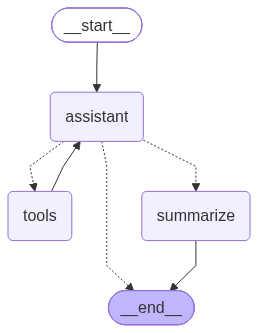

In [21]:
from graph import create_graph
graph_m1_with_summary = create_graph().compile()
from IPython.display import Image, display
try:
    display(Image(graph_mo.get_graph().draw_mermaid_png()))
except Exception as ex:
    print("Couldnot render png")